# Industrial Machine Failure Prediction
MCA project using the UCI AI4I 2020 Predictive Maintenance dataset.

Run cells in order in Google Colab. Upload `ai4i2020.csv` when prompted.

In [ ]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib


In [ ]:
from google.colab import files
uploaded = files.upload()
csv_name = next(iter(uploaded))
print('Uploaded:', csv_name)


Saving ai4i2020.csv to ai4i2020.csv
Uploaded: ai4i2020.csv


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score, ConfusionMatrixDisplay
from pathlib import Path
df = pd.read_csv(csv_name)
print(df.shape); display(df.head()); display(df['Machine failure'].value_counts(normalize=True))


(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,proportion
Machine failure,
0,0.9661
1,0.0339


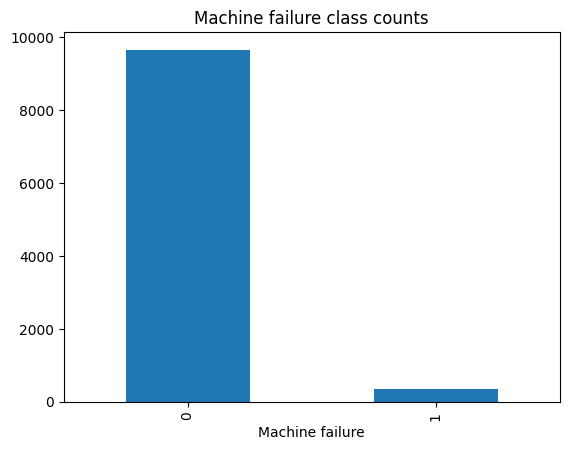

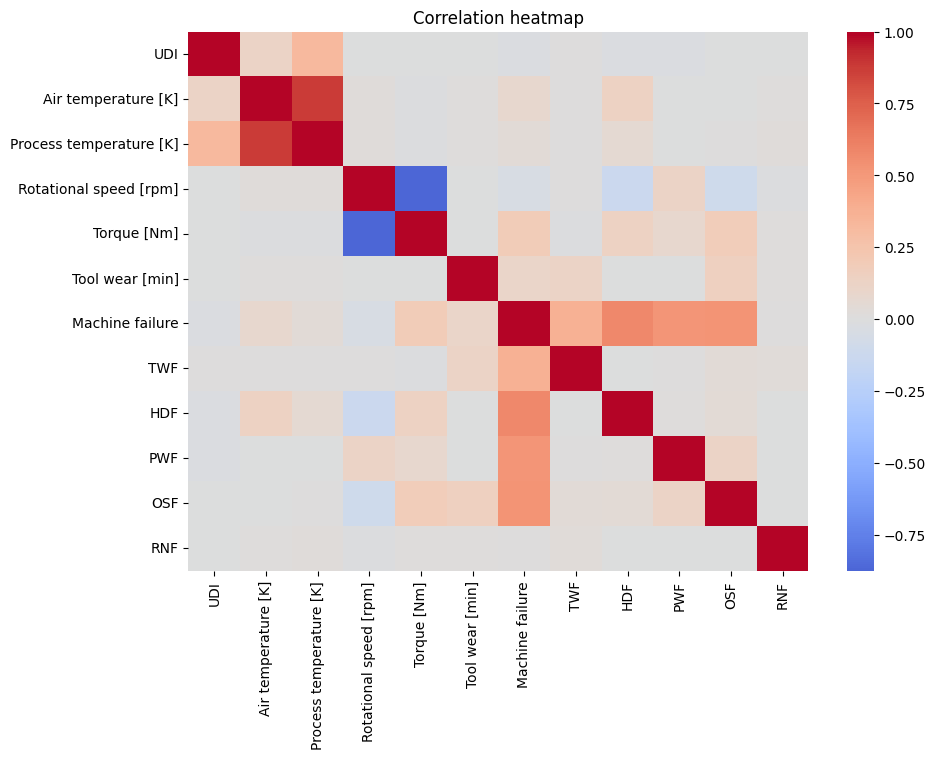

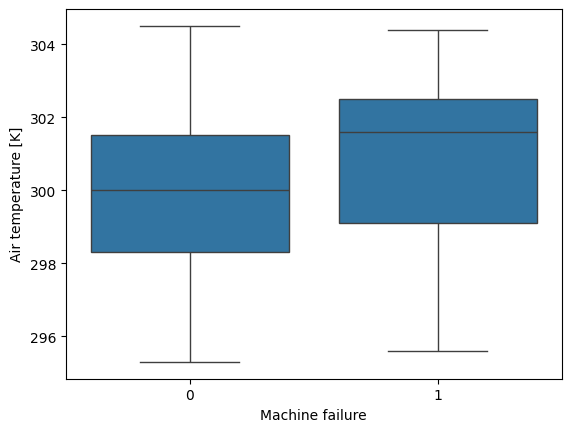

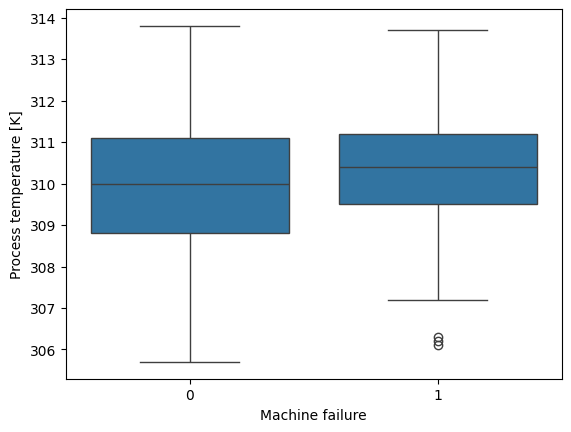

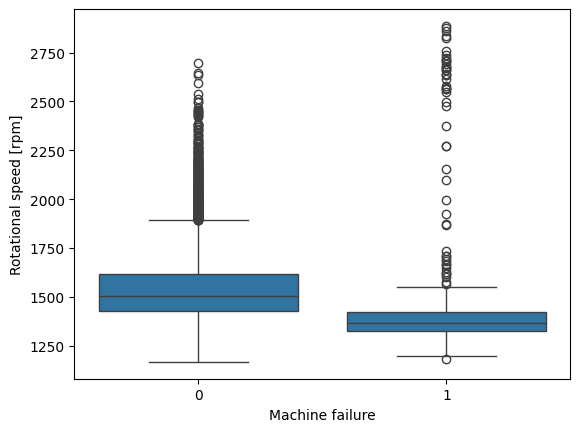

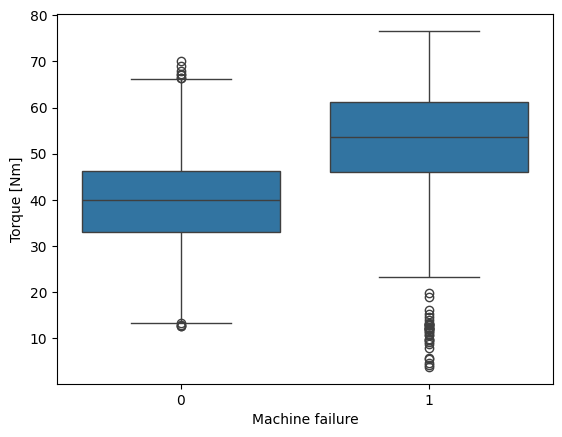

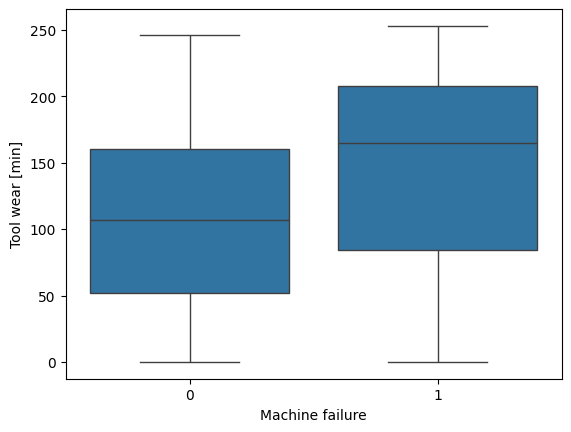

In [ ]:
df['Machine failure'].value_counts().plot(kind='bar', title='Machine failure class counts'); plt.show()
numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(10,7)); sns.heatmap(numeric.corr(), cmap='coolwarm', center=0); plt.title('Correlation heatmap'); plt.show()
for col in ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']:
    sns.boxplot(data=df, x='Machine failure', y=col); plt.show()


In [ ]:
target = 'Machine failure'
leakage = ['TWF','HDF','PWF','OSF','RNF']
drop_cols = ['UDI','Product ID'] + leakage
X = df.drop(columns=[target] + [c for c in drop_cols if c in df.columns])
y = df[target].astype(int)
categorical = [c for c in X.columns if X[c].dtype == 'object']
numeric_features = [c for c in X.columns if c not in categorical]
preprocess = ColumnTransformer([
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)


Train: (8000, 6) Test: (2000, 6)


## Example prediction for a new machine
Edit the sensor values below to test an unseen machine record.

In [ ]:
import os
import shutil

os.makedirs("models", exist_ok=True)

shutil.move(
    "best_machine_failure_model.joblib",
    "models/best_machine_failure_model.joblib"
)

shutil.move(
    "model_metadata.joblib",
    "models/model_metadata.joblib"
)

print("Model files uploaded successfully!")

Model files uploaded successfully!


In [ ]:
new_machine = pd.DataFrame([{'Type':'M','Air temperature [K]':300.0,'Process temperature [K]':310.0,'Rotational speed [rpm]':1500,'Torque [Nm]':40.0,'Tool wear [min]':120}])
print('Predicted failure:', int(best_model.predict(new_machine)[0]))
print('Failure probability:', round(float(best_model.predict_proba(new_machine)[0,1]),4))


Predicted failure: 0
Failure probability: 0.0032


In [ ]:
!pip install -q streamlit pandas numpy scikit-learn joblib


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O cloudflared.deb

!dpkg -i cloudflared.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack cloudflared.deb ...
Unpacking cloudflared (2026.10.7) ...
Setting up cloudflared (2026.10.7) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared --version

cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)


In [ ]:
import os

print("App exists:", os.path.exists("app.py"))

print("Model exists:", os.path.exists(
    "models/best_machine_failure_model.joblib"
))

print("Metadata exists:", os.path.exists(
    "models/model_metadata.joblib"
))

App exists: True
Model exists: True
Metadata exists: True


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [ ]:
import time
time.sleep(5)

!cat streamlit.log



2026-11-04 13:56:19.007 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.187.158.86:8501



In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

2026-11-04T13:57:34Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-04T13:57:34Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-04T13:57:38Z INF +--------------------------------------------------------------------------------------------+
2026-11-04T13:57:38Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-04T13:57:38Z INF |  https://tracker-aware-coleman-secretariat.trycloudfla